# Checkpoint 1: Raw ECG -> Model Input
**Project:** *Lead I or Twelve? Measuring How Much Heart-Disease Signal Survives a Wearable-Style Single-Lead ECG*

## Setup

In [2]:
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "wfdb", "neurokit2"], check=True)

import os, ast, time, random, warnings, urllib.request
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
import neurokit2 as nk

warnings.filterwarnings("ignore", category=RuntimeWarning)
SEED = 42
random.seed(SEED); np.random.seed(SEED)
DATA_DIR = "/content/ptb-xl" if IN_COLAB else os.path.join("data", "ptb-xl")
SAMPLING_RATE = 100

In [2]:
import threading
import requests

BASE_URL = "https://physionet-open.s3.amazonaws.com/ptb-xl/1.0.3/"
_local = threading.local()

def _session():
    # one keep-alive connection per thread instead of a new TLS handshake per file
    if not hasattr(_local, "s"):
        _local.s = requests.Session()
    return _local.s

def _fetch(rel_path, retries=5):
    dest = os.path.join(DATA_DIR, rel_path)
    if os.path.exists(dest) and os.path.getsize(dest) > 0:
        return
    os.makedirs(os.path.dirname(dest), exist_ok=True)
    for attempt in range(retries):
        try:
            # timeout = (connect, read): a stalled connection raises instead of hanging forever
            r = _session().get(BASE_URL + rel_path, timeout=(10, 30))
            r.raise_for_status()
            with open(dest + ".part", "wb") as fh:
                fh.write(r.content)
            os.replace(dest + ".part", dest); return
        except Exception:
            if attempt == retries - 1: raise
            time.sleep(2 ** attempt)

for f in ["ptbxl_database.csv", "scp_statements.csv"]:
    _fetch(f)
_db = pd.read_csv(os.path.join(DATA_DIR, "ptbxl_database.csv"))
todo = [p + ext for p in _db["filename_lr"] for ext in (".hea", ".dat")
        if not os.path.exists(os.path.join(DATA_DIR, p + ext))]
print(f"{len(todo):,} files to download")
t0 = time.time()
with ThreadPoolExecutor(max_workers=16) as pool:
    for i, _ in enumerate(pool.map(_fetch, todo), 1):
        if i % 2000 == 0 or i == len(todo):
            print(f"  {i:,}/{len(todo):,}  ({time.time() - t0:.0f}s)")
print("data ready:", os.path.abspath(DATA_DIR))


0 files to download
data ready: /Users/hudsonpifer/Deep Learning/Project1/data/ptb-xl


## 1. Number of samples and features

In [3]:
db = pd.read_csv(os.path.join(DATA_DIR, "ptbxl_database.csv"), index_col="ecg_id")
db["scp_codes"] = db["scp_codes"].apply(ast.literal_eval)
scp = pd.read_csv(os.path.join(DATA_DIR, "scp_statements.csv"), index_col=0)

cache = os.path.join(DATA_DIR, "X100_float32.npy")
if os.path.exists(cache):
    X_all = np.load(cache, mmap_mode="r")
else:
    def _read(p): return wfdb.rdsamp(os.path.join(DATA_DIR, p))[0].astype(np.float32)
    with ThreadPoolExecutor(max_workers=16) as pool:
        X_all = np.stack(list(pool.map(_read, db.filename_lr)))
    np.save(cache, X_all)
LEADS = wfdb.rdheader(os.path.join(DATA_DIR, db.filename_lr.iloc[0])).sig_name

print(f"Recordings (samples): {len(db):,} from {db.patient_id.nunique():,} patients")
print(f"Waveform array: {X_all.shape} = (recordings, time steps, leads)  ->  "
      f"{X_all.shape[1]} × {X_all.shape[2]} = {X_all.shape[1]*X_all.shape[2]:,} raw values per recording")
print("Leads:", LEADS)

Recordings (samples): 21,799 from 18,869 patients
Waveform array: (21799, 1000, 12) = (recordings, time steps, leads)  ->  1000 × 12 = 12,000 raw values per recording
Leads: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


## 2. Target variable and feature types
Each recording carries cardiologist ECG statements. The 44 diagnostic statements map to 5 superclasses: NORM, MI (myocardial infarction), STTC (ST/T change), CD (conduction disturbance), HYP (hypertrophy).
* Primary target abnormal (binary): 1 if any of MI/STTC/CD/HYP is present, 0 if only NORM.
* Secondary target (5 binary columns, multi-label): used for the per-category breakdown.
* Recordings with no diagnostic superclass have no ground truth and are excluded.

In [4]:
SUPER, ABN = ["NORM", "MI", "STTC", "CD", "HYP"], ["MI", "STTC", "CD", "HYP"]
diag_map = scp.loc[scp.diagnostic == 1, "diagnostic_class"].to_dict()
db["super"] = db.scp_codes.apply(lambda codes: {diag_map[c] for c in codes if c in diag_map})
for c in SUPER:
    db[c] = db["super"].apply(lambda s: int(c in s))
db["abnormal"] = (db[ABN].sum(axis=1) > 0).astype(int)

no_label = db[SUPER].sum(axis=1) == 0
df = db.loc[~no_label].copy()
row_of = pd.Series(np.arange(len(db)), index=db.index)
X = np.asarray(X_all[row_of[df.index].values])
print(f"Excluded (no diagnostic label): {no_label.sum():,}  ->  usable: {len(df):,} recordings")
print(f"Multi-label recordings (≥2 superclasses): {(df[SUPER].sum(axis=1) >= 2).mean():.1%}")
print(f"Missing values in waveforms: {int(np.isnan(X).sum())}")

pd.DataFrame({
    "variable": ["abnormal (target)", "NORM/MI/STTC/CD/HYP (target)", "12-lead ECG waveform (input)"],
    "type": ["binary categorical (0/1)", "multi-label binary (5 × 0/1)", "numeric multichannel time series, mV"],
    "shape per recording": ["1", "5", "1000 × 12"],
}).set_index("variable")

Excluded (no diagnostic label): 411  ->  usable: 21,388 recordings
Multi-label recordings (≥2 superclasses): 24.1%
Missing values in waveforms: 0


,type,shape per recording
variable,,
abnormal (target),binary categorical (0/1),1
NORM/MI/STTC/CD/HYP (target),multi-label binary (5 × 0/1),5
12-lead ECG waveform (input),"numeric multichannel time series, mV",1000 × 12


## 3. Visualization: target imbalance

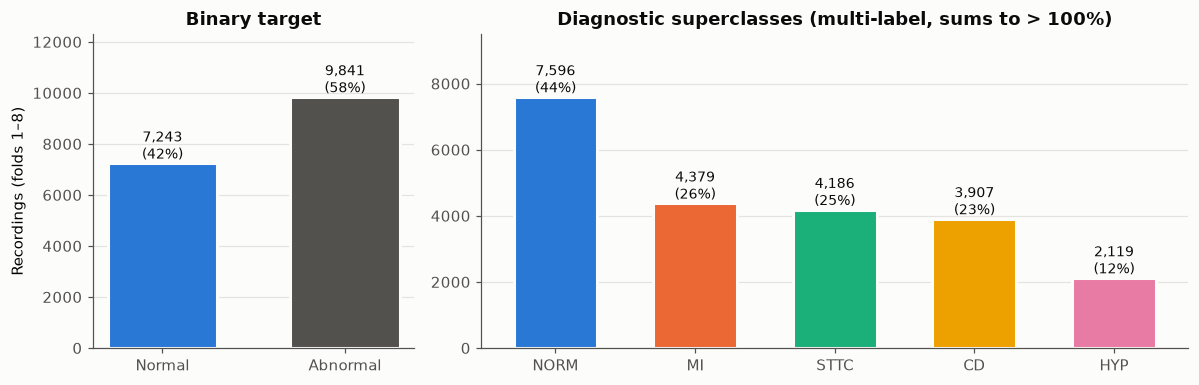

In [5]:
COL = {"NORM": "#2a78d6", "MI": "#eb6834", "STTC": "#1baf7a", "CD": "#eda100", "HYP": "#e87ba4"}
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True, "axes.titleweight": "bold", "figure.dpi": 110})

train = df[df.strat_fold <= 8]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 2.2]})
for ax, labels, vals, colors, title in [
    (axes[0], ["Normal", "Abnormal"], train.abnormal.value_counts().reindex([0, 1]).values,
     [COL["NORM"], INK2], "Binary target"),
    (axes[1], SUPER, train[SUPER].sum().values, [COL[c] for c in SUPER],
     "Diagnostic superclasses (multi-label, sums to > 100%)")]:
    bars = ax.bar(labels, vals, color=colors, width=0.6, edgecolor=SURF, linewidth=2)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v, f"{v:,}\n({v/len(train):.0%})", ha="center", va="bottom", fontsize=9)
    ax.set_title(title); ax.set_ylim(0, max(vals) * 1.25); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Recordings (folds 1–8)")
plt.tight_layout(); plt.show()

## 4. What we observed
* Moderate class imbalance: 58% abnormal vs 42% normal. Among the categories, HYP is the minority (12%), about half as common as MI, STTC or CD.
* Repeat patients: 2,111 patients have more than one recording, so the split must be by patient.

## 5. Preprocessing techniques
* Scaling: Standard Scaler fit on training data
* Encoding: not needed, since every input is numeric and the targets are already 0/1
* Imputation: Median, fot on training data

In [6]:
split = np.select([df.strat_fold <= 8, df.strat_fold == 9], ["train", "val"], "test")
tr = split == "train"
pats = {s: set(df.patient_id[split == s]) for s in ["train", "val", "test"]}
assert not (pats["train"] & pats["val"] or pats["train"] & pats["test"] or pats["val"] & pats["test"])
print("✓ No patient appears in more than one split.",
      {s: int((split == s).sum()) for s in ["train", "val", "test"]})

LEAD_SETS = {"A_12lead": LEADS, "B_limb": ["I", "II", "III", "AVR", "AVL", "AVF"], "C_leadI": ["I"]}
LEAD_SETS = {k: [LEADS.index(l) for l in v] for k, v in LEAD_SETS.items()}
mu = np.array([X[tr, :, k].mean() for k in range(12)], dtype=np.float32)
sd = np.array([X[tr, :, k].std() for k in range(12)], dtype=np.float32)

def to_model_input(Xs, lead_idx):
    return np.ascontiguousarray(((Xs[:, :, lead_idx] - mu[lead_idx]) / sd[lead_idx]).transpose(0, 2, 1))

print("Train per-lead std (mV):", dict(zip(LEADS, sd.round(2).tolist())))

✓ No patient appears in more than one split. {'train': 17084, 'val': 2146, 'test': 2158}
Train per-lead std (mV): {'I': 0.1599999964237213, 'II': 0.1599999964237213, 'III': 0.1599999964237213, 'AVR': 0.14000000059604645, 'AVL': 0.14000000059604645, 'AVF': 0.14000000059604645, 'V1': 0.23000000417232513, 'V2': 0.33000001311302185, 'V3': 0.33000001311302185, 'V4': 0.28999999165534973, 'V5': 0.27000001072883606, 'V6': 0.2800000011920929}


In [7]:
PRE, POST = 25, 50
MORPH = ["r_amp", "s_amp", "qrs_width_ms", "st80", "t_amp", "sig_std"]
RHYTHM = ["hr_bpm", "rr_sdnn_ms", "rr_rmssd_ms", "n_beats"]

def extract_features(sig):
    out = {k: np.nan for k in RHYTHM}
    out.update({f"{l}_{m}": np.nan for l in LEADS for m in MORPH})
    for k, l in enumerate(LEADS):
        out[f"{l}_sig_std"] = float(sig[:, k].std())
    try:
        _, info = nk.ecg_peaks(nk.ecg_clean(sig[:, 0], sampling_rate=SAMPLING_RATE), sampling_rate=SAMPLING_RATE)
        r = np.asarray(info["ECG_R_Peaks"])
    except Exception:
        return out
    r = r[(r >= PRE) & (r < 1000 - POST)]
    if len(r) < 3:
        return out
    rr = np.diff(r) * 1000 / SAMPLING_RATE
    out.update(hr_bpm=60000 / rr.mean(), rr_sdnn_ms=rr.std(), rr_rmssd_ms=np.sqrt(np.mean(np.diff(rr) ** 2)),
               n_beats=len(r))
    med = np.median(np.stack([sig[i - PRE:i + POST] for i in r]), axis=0)
    med = med - med[PRE - 10:PRE - 5].mean(axis=0)
    slope = np.abs(np.diff(med, axis=0))[PRE - 12:PRE + 12]
    for k, l in enumerate(LEADS):
        b, qrs = med[:, k], med[PRE - 6:PRE + 7, k]
        active = np.flatnonzero(slope[:, k] > 0.15 * slope[:, k].max())
        out[f"{l}_r_amp"], out[f"{l}_s_amp"] = qrs.max(), qrs.min()
        out[f"{l}_qrs_width_ms"] = (active[-1] - active[0] + 2) * 1000 / SAMPLING_RATE if len(active) else np.nan
        out[f"{l}_st80"] = b[PRE + 8]
        tw = b[PRE + 15:PRE + 45]
        out[f"{l}_t_amp"] = tw[np.argmax(np.abs(tw))]
    return out

feat_cache = os.path.join(DATA_DIR, "handcrafted_features.parquet")
if os.path.exists(feat_cache):
    F = pd.read_parquet(feat_cache).loc[df.index]
else:
    with ThreadPoolExecutor(max_workers=os.cpu_count()) as pool:
        F = pd.DataFrame(list(pool.map(extract_features, X)), index=df.index)
    F.to_parquet(feat_cache)
print(f"Baseline feature matrix: {F.shape}; recordings needing imputation: {int(F.hr_bpm.isna().sum())}")

Baseline feature matrix: (21388, 76); recordings needing imputation: 2


## 6. Final set of input features

In [8]:
def baseline_features(cfg):
    return RHYTHM + [f"{LEADS[i]}_{m}" for i in LEAD_SETS[cfg] for m in MORPH]

pd.DataFrame([{"config": k, "leads": ", ".join(LEADS[i] for i in v),
               "deep model input": f"{to_model_input(X[:1], v).shape[1]} × {to_model_input(X[:1], v).shape[2]} standardized waveform",
               "baseline features": len(baseline_features(k))} for k, v in LEAD_SETS.items()]).set_index("config")

,leads,deep model input,baseline features
config,,,
A_12lead,"I, II, III, AVR, AVL, AVF, V1, V2, V3, V4, V5, V6",12 × 1000 standardized waveform,76
B_limb,"I, II, III, AVR, AVL, AVF",6 × 1000 standardized waveform,40
C_leadI,I,1 × 1000 standardized waveform,10


* Deep model: the standardized raw waveform, a C × 1000 tensor (C = 12 / 6 / 1).
* Baseline: heart rate, R-R SDNN, R-R RMSSD and beat count, plus 6 features per lead (R amplitude, S amplitude, QRS width, ST level at +80 ms, T amplitude, signal std): 76 / 40 / 10 features.

## 7. The ML problem
Supervised binary classification: is a 10-second ECG normal or abnormal? Plus a multi-label classification over the 5 superclasses, to see which categories are lost when leads are removed. The target is a category, not a quantity, so this is classification, not regression.

## 8. Proposed ML methods and why
* Logistic regression (baseline): The classic pre-deep-learning ECG pipeline; interpretable; runs the same way at 12, 6 or 1 lead
* Gradient-boosted trees (baseline): Non-linear, so a deep-learning win can't be put down to a straight-line decision boundary
* 1D residual CNN (main model): Learns shape patterns wherever they occur in the signal; residual blocks train stably at depth